In [1]:
# Figure 1: Summary of test results

In [ ]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from fast_o3_iv import utils as tools
from fast_o3_iv.config import PROCESSED_DATA_DIR

In [ ]:
df = pd.read_csv(PROCESSED_DATA_DIR / "figure_data" / "Table2_test_metrics.csv")
df = df.rename(columns={"Unnamed: 0": "metric"}).set_index("metric")

In [ ]:
# helper funcs and plot settings
tools.set_matplotlib_font("Arial")

row_labels = ["MLR", "XGB", "GPR"]
col_labels = ["Local", "Global"]  

# main titles for each subplot
metric_titles = {
    "ens_clim":     "a) Ensemble-mean climatology",
    "ens_trend":    "b) Ensemble-mean linear trend",
    "resid_sd":     "c) Internal variability SD ",
    "resid_q90":    "d) Internal variability q90",
    "pgt_q90":      "e) Internal variability P(>q90)",
    "emd_to_noise": "f) Internal variability EMD-to-noise",
}

# sub-titles for each subplot
summary_method = {
    "ens_clim":     "Area-weighted RMSE (ppbv)",
    "ens_trend":    "Area-weighted RMSE (ppbv/40yr)",
    "resid_sd":     "Area-weighted RMSE (ppbv)",
    "resid_q90":    "Area-weighted RMSE (ppbv)",
    "pgt_q90":      "Area-weighted RMSE (unitless)",
    "emd_to_noise": "Area-weighted mean (unitless)",
}

# 2x3 grid of metrics for each subplot
metric_grid = [
    ("ens_clim", "ens_trend", "resid_sd"),
    ("resid_q90", "pgt_q90", "emd_to_noise"),
]

bar_colors = [
    ["#F06292", "#D81B60"],  
    ["#64B5F6", "#1E88E5"], 
    ["#FFD54F", "#FFC107"],  
]

# helper funcs
def get_value(metric, model, scope):
    """Look up a value from the summary dataframe (Table2_test_metrics)."""
    col = f"{model}-{scope.lower()}"

    # GPR-global will be nan so just return nan
    if col not in df.columns or metric not in df.index:
        return np.nan 
    
    val = df.loc[metric, col]
    return float(val) if pd.notna(val) else np.nan


def draw_mini_bars(ax, metric, font=8):
    """Draw the pretty barplots for each metric."""

    # for each metric, build a 3x2 matrix of metrics calculated for each 
    # <model>-<scope> pair (aka MLR-local, GPR-global, etc)
    M = np.full((len(row_labels), len(col_labels)), np.nan, dtype=float)
    for i, model in enumerate(row_labels):
        for j, scope in enumerate(col_labels):
            M[i, j] = get_value(metric, model, scope)
    x = np.arange(M.shape[0], dtype=float)

    # barplot visuals 
    width = 0.34 # width of individual bars
    offsets = (-width / 2, width / 2) # shift bar pairs left/right of center  
    hatches = ("", "//")  # local, global (to differentiate not just by color!!)                    

    # pick y-lim values that make sense
    finite = M[np.isfinite(M)]
    if finite.size == 0:
        ax.set_ylim(0.0, 1.0)
    else:
        lo, hi = float(finite.min()), float(finite.max())
        if lo >= 0:
            # all-positive data: start at 0 then pad the top by 20%.
            ax.set_ylim(0.0, hi * 1.20 if hi > 0 else 1.0)
        else:
            # data crosses zero so we pad both ends 
            span = hi - lo if not np.isclose(hi, lo) else max(1.0, abs(hi))
            pad = 0.12 * span
            ax.set_ylim(lo - pad, hi + pad)

    # get y-lim once set, to add text above the bars
    y0, y1 = ax.get_ylim()
    dy = y1 - y0 

    # draw each bar : loop through data in the <model>-<scope> matrix
    for i in range(M.shape[0]):        
        for j in range(M.shape[1]):   
            xx = x[i] + offsets[j]
            v = M[i, j]

            if np.isfinite(v):

                # add barplot
                ax.bar(
                    xx, v, width=width,
                    color=bar_colors[i][j],
                    edgecolor="0.25", linewidth=0.5,
                    hatch=hatches[j], zorder=3,
                )

                # add text above barplot with the y-value
                ax.text(
                    xx, v + 0.02 * dy, f"{v:.2g}",
                    ha="center", va="bottom", fontsize=font - 1,
                )
            else:
                # if missing: add 'NA' label
                base = max(0.0, y0)
                ax.bar(
                    xx, 0.001 * dy, width=width, bottom=base,
                    color="white", edgecolor="0.6", linewidth=0.7,
                    hatch="xx", zorder=3,
                )
                ax.text(
                    xx, base + 0.02 * dy, "NA",
                    ha="center", va="bottom", fontsize=font - 1, color="0.45",
                )

    # more visual settings
    ax.set_xticks(x)
    ax.set_xticklabels(row_labels, fontsize=font)
    ax.tick_params(axis="y", labelsize=font - 1, length=2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

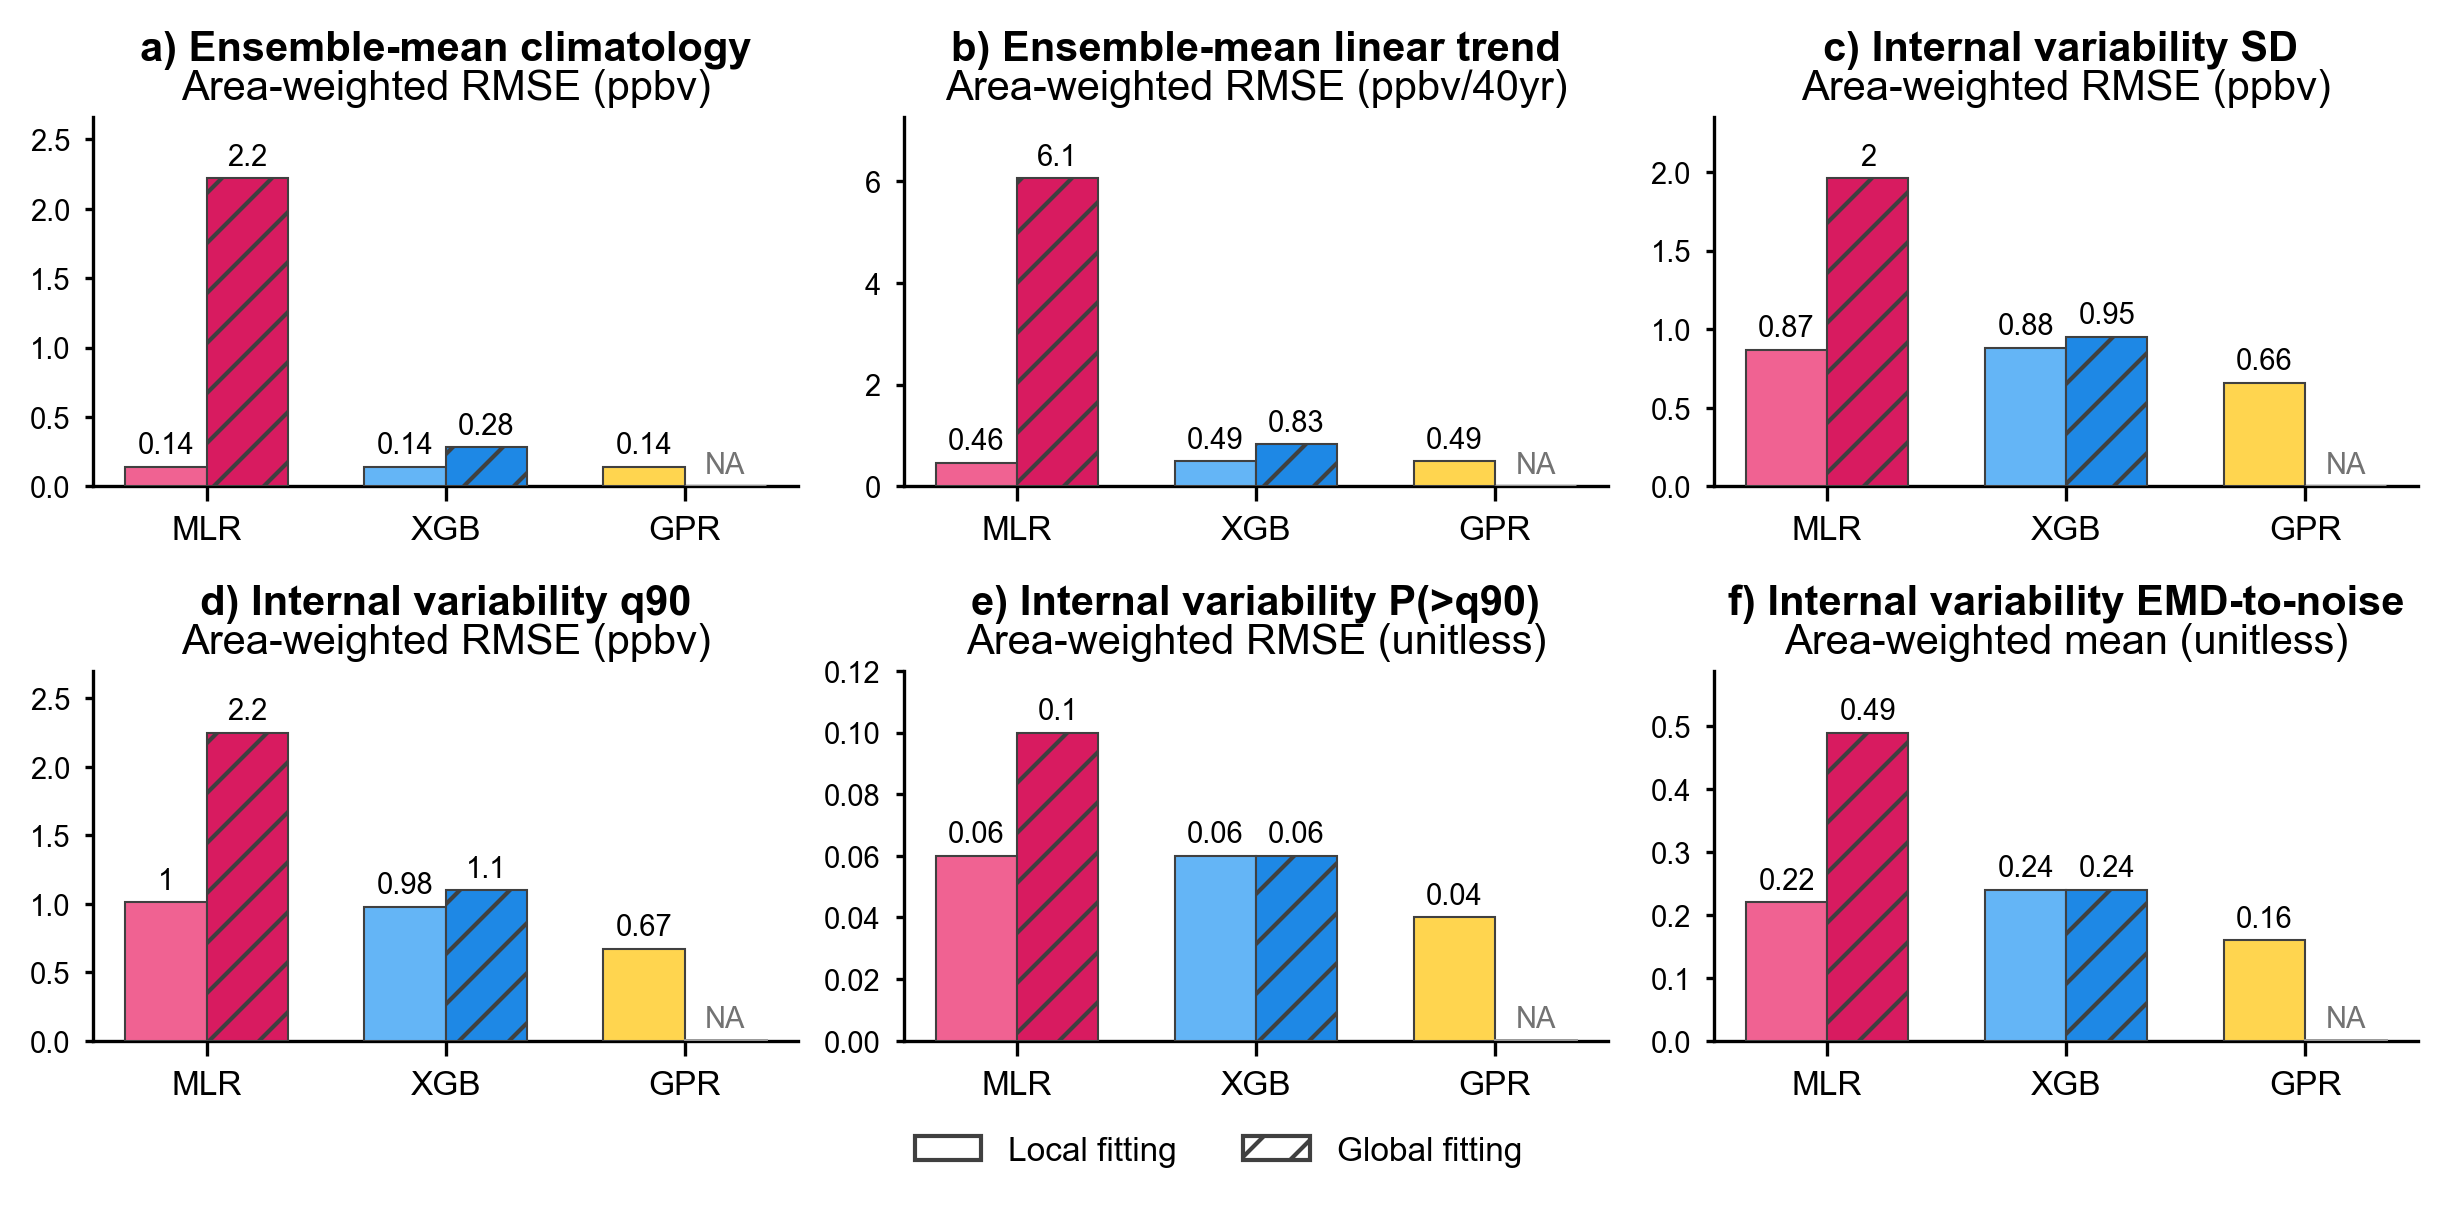

In [ ]:
# create the figure
fig = plt.figure(figsize=(10, 4), dpi=300)

# one panel per metric
gs = fig.add_gridspec(nrows=2, ncols=3, width_ratios=[1, 1, 1], wspace=0.15, hspace=0.5)

for r, row_metrics in enumerate(metric_grid):
    for c, metric in enumerate(row_metrics):
        ax = fig.add_subplot(gs[r, c])

        # add data
        draw_mini_bars(ax, metric)

        pos = ax.get_position()
        x_mid = 0.5 * (pos.x0 + pos.x1)

        # add titles
        fig.text(
            x_mid, pos.y1 + 0.04,
            metric_titles.get(metric, metric),
            ha="center", va="bottom", fontsize=10, fontweight="bold",
        )

        # add subtitles
        fig.text(
            x_mid, pos.y1 + 0.008,
            summary_method.get(metric, metric),
            ha="center", va="bottom", fontsize=10,
        )

# legend
fig.legend(
    handles=[
        Patch(facecolor="white", edgecolor="0.25", hatch="", label="Local fitting"),
        Patch(facecolor="white", edgecolor="0.25", hatch="//", label="Global fitting"),
    ],
    loc="lower center", ncol=2, frameon=False,
    bbox_to_anchor=(0.5, -0.02), fontsize=8,
)

plt.show()

# fig.savefig("tabular_metrics_grid_monthly_mda8_only.png", dpi=300, bbox_inches="tight")